# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zahid1704/ML_Project/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

How the queue is built. I take every page with at least 200 impressions in March 2026 (84,833 pages) and compare its click-through rate with the median CTR of pages in the same position tier. 42,414 pages fall below their tier median and enter the queue. This is about half of all pages, which is expected because a median splits pages in two, so the size of the queue is not a finding. The ranking is what matters: each page is ordered by estimated missed clicks, meaning the clicks it would have received at its tier’s typical CTR minus the clicks it actually got.

Position correction. Search Console’s position sum appears to be zero-based (the smallest average position in my data was 0.02, which is impossible for a real ranking), so I added 1 to every average position before assigning tiers. After the fix the smallest position is 1.02.

Actions in the queue. 22,302 pages are marked “review title and meta description” (positions 4-10), 9,002 “improve content coverage, then review title and meta” (positions 11-20), 1,763 “check the search result page before editing” (positions 1-3), and 9,347 “monitor only” (positions 21 and below).

Reason codes. high_volume_low_ctr means at least 2,000 March impressions, so even a small CTR gap is worth many clicks. low_ctr_for_position means fewer impressions, so the gap is more likely to be noise.

What the top of the queue looks like. All of the top 10 are high_volume_low_ctr, with 71K to 212K impressions each and between 1 and 289 clicks. Eight of the ten sit at positions 4-10 and two at positions 1-3. They come from six clients, with one client holding three of the ten and two clients holding two each.

What could make the top rows wrong. A page with over 100,000 impressions and a handful of clicks looks more like a data or tracking artifact, an average position blended across very different queries, or a query mix where the search page answers the question without a click. A person should check these pages before anyone edits a title.

What the score means. It ranks pages to look at first. It does not say a title is the cause of low CTR, or that an edit will raise clicks. In my week 6 audit this rule ranked April CTR gaps with an AUC of 0.774 on held-out clients, close to the random forest’s 0.799, so I use the simpler rule, which a reviewer can read.

Limitation. My earlier weeks used the position before this correction, so tier boundaries in those results were slightly shifted. I expect the conclusions to hold, but I did not rerun them.

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import time
import duckdb
import numpy as np
import pandas as pd
from google.colab import userdata

start = time.time()

con = duckdb.connect()
con.execute(f"CREATE SECRET (TYPE huggingface, TOKEN '{userdata.get('HF_TOKEN')}')")

path = "hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-03/*.parquet"

pages = con.sql(f"""
SELECT client_hash_id, content_hash_id,
       SUM(gsc_impressions) AS impressions,
       SUM(gsc_clicks) AS clicks,
       SUM(gsc_sum_position) * 1.0 / SUM(gsc_impressions) AS avg_position
FROM read_parquet('{path}')
WHERE gsc_impressions > 0
GROUP BY client_hash_id, content_hash_id
HAVING SUM(gsc_impressions) >= 200
""").df()

pages.to_csv("march_pages.csv", index=False)
print("Pages:", len(pages))
print("Seconds:", round(time.time() - start))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pages: 84833
Seconds: 236


In [6]:
pages = pd.read_csv("march_pages.csv")

# Search Console stores position sums starting from 0, so add 1 to get the real position
print("Smallest position before fix:", round(pages["avg_position"].min(), 3))
pages["avg_position"] = pages["avg_position"] + 1
print("Smallest position after fix:", round(pages["avg_position"].min(), 3))

pages["ctr"] = pages["clicks"] / pages["impressions"]
pages["tier"] = pd.cut(pages["avg_position"], [0, 3, 10, 20, 1000],
                       labels=["pos 1-3", "pos 4-10", "pos 11-20", "pos 21+"])

pages["expected_ctr"] = pages.groupby("tier", observed=True)["ctr"].median().reindex(pages["tier"]).values
pages["missed_clicks"] = pages["expected_ctr"] * pages["impressions"] - pages["clicks"]

queue = pages[pages["missed_clicks"] > 0].copy()
print("Pages in queue:", len(queue))

Smallest position before fix: 0.02
Smallest position after fix: 1.02
Pages in queue: 42414


In [7]:
queue["reason_code"] = np.where(queue["impressions"] >= 2000, "high_volume_low_ctr", "low_ctr_for_position")

queue["action"] = queue["tier"].map({
    "pos 1-3": "check the search result page before editing",
    "pos 4-10": "review title and meta description",
    "pos 11-20": "improve content coverage, then review title and meta",
    "pos 21+": "monitor only",
}).astype(str)

queue = queue.sort_values("missed_clicks", ascending=False).reset_index(drop=True)
queue["rank"] = queue.index + 1

print(queue["action"].value_counts())
queue.head(10).round(4)

action
review title and meta description                       22302
monitor only                                             9347
improve content coverage, then review title and meta     9002
check the search result page before editing              1763
Name: count, dtype: int64


,client_hash_id,content_hash_id,impressions,clicks,avg_position,ctr,tier,expected_ctr,missed_clicks,reason_code,action,rank
0,client_23a62021009f63c4,content_44f34c0a90047651,212404.0,24.0,1.6659,0.0001,pos 1-3,0.0017,329.6384,high_volume_low_ctr,check the search result page before editing,1
1,client_73cda7b4e4f265ea,content_8e1334d6356668e3,134984.0,1.0,3.6930,0.0000,pos 4-10,0.0022,292.8272,high_volume_low_ctr,review title and meta description,2
2,client_62f4a7e64f5e0096,content_34a70fea29d15f24,143019.0,43.0,4.1661,0.0003,pos 4-10,0.0022,268.3175,high_volume_low_ctr,review title and meta description,3
3,client_62f4a7e64f5e0096,content_7c6373141eae744a,132593.0,83.0,6.9485,0.0006,pos 4-10,0.0022,205.6226,high_volume_low_ctr,review title and meta description,4
4,client_73cda7b4e4f265ea,content_fec55986a1868d62,124075.0,1.0,1.3084,0.0000,pos 1-3,0.0017,205.5766,high_volume_low_ctr,check the search result page before editing,5
5,client_9958f0a7ae1df715,content_cd3d932d4e1c8db0,89332.0,4.0,8.8318,0.0000,pos 4-10,0.0022,190.4540,high_volume_low_ctr,review title and meta description,6
6,client_a80fca3f171ed1de,content_046fc480045b88f5,83788.0,6.0,8.2083,0.0001,pos 4-10,0.0022,176.3860,high_volume_low_ctr,review title and meta description,7
7,client_a80fca3f171ed1de,content_9540d884af3e41fd,82376.0,11.0,9.0052,0.0001,pos 4-10,0.0022,168.3125,high_volume_low_ctr,review title and meta description,8
8,client_e547b89c05043229,content_8d7d99f109e19aa2,203497.0,289.0,3.4686,0.0014,pos 4-10,0.0022,153.9633,high_volume_low_ctr,review title and meta description,9
9,client_73cda7b4e4f265ea,content_425715547c6a3ea8,71513.0,3.0,7.9834,0.0000,pos 4-10,0.0022,152.6664,high_volume_low_ctr,review title and meta description,10


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

Intended use. The queue is for a content or SEO editor who has limited time and needs to decide which pages to look at first. They would open the ranked list, check the top pages by hand, and decide whether a title, meta description, or content edit is worth making. It is a way to order a review list, not a decision about what to change. A reviewer who can check about 20 to 50 pages a week would start from the top of the queue and work down.

What the score is. A page’s rank comes from estimated missed clicks: the clicks it would have received at its position tier’s typical CTR minus the clicks it actually got in March 2026. The reason code and action label tell the reviewer why the page is there and what to look at first.

Where it stops being valid.

One month. The queue uses March 2026 only, so seasonal dips or one-off events can put pages in the queue that would not appear in another month.
Pages with enough volume. Only pages with at least 200 impressions are included, and in my week 6 audit I also required visibility in April to build the label, so the results describe pages that stayed visible, not every page.
Position tiers are an approximation. Pages near a tier boundary (for example, average position 10.2 versus 9.8) are compared against different groups, so their ranking is less certain.
Average position can hide a mix. A page’s average position blends many queries, so a low CTR may reflect a few high-ranking queries and many low-ranking ones. The queue cannot see individual queries.
Low CTR has many causes. Informational queries can be answered on the search page without a click, and ads or other result features can take clicks. The queue cannot tell these apart from a weak title.
Observational only. The data shows what happened, not what would happen after an edit. The queue cannot say that changing a title will raise clicks.
Small edge over a simple rule. In my week 6 audit the rule reached an AUC of 0.774 on held-out clients, against 0.799 for the random forest, so I use the simple rule, and the model adds little.
Concentration. [If you ran the cell: “The top 50 pages come from N clients, with one client holding X of them, so the queue reflects a few clients more than the whole set.”]
Position data. The position sum in the data is zero-based, and I corrected it by adding 1. Earlier weeks used the uncorrected value.

Not claimed. This work does not claim to explain Google’s ranking, to predict future traffic for any single page, or to show that any action will recover clicks.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

Before anyone acts on a queue row, a person must check:

Is the data believable? For pages with very high impressions and almost no clicks (several of my top 10 have 70K to 210K impressions and fewer than 300 clicks), check Search Console directly for a tracking gap or an average position blended across very different queries.
What does the search result page look like? Search the target query by hand. Ads, answer boxes, or other features may explain a low CTR, and a title edit would not fix that.
Does the query intent explain it? Informational queries are often answered on the search page without a click, so a low CTR may be normal for that page.
Is it a one-month blip? Look at the page’s CTR across several months before deciding. A page that dipped only in March does not need the same action as a page that has been low all year.
Could another page explain it? Check whether a related page on the same site took the traffic.
Is the page close to a tier boundary? A page at position 10.1 is compared against a different group than one at 9.9, so treat its rank with extra caution.
Is the action realistic? The reviewer decides whether the suggested action (for example, rewriting a title) fits the page and the client, and records what was changed so the result can be checked later.

Review rule of thumb. Start at the top of the queue and review a fixed number of pages per week (for example 20). Record each decision as act, skip, or investigate, with one line of reasoning. If most of the top pages are skipped for the same reason, that is a signal to revisit the queue’s rules and not the pages.

No-go list: what should never be automated.

Automatically rewriting titles or meta descriptions. The queue ranks pages to review. It does not know why CTR is low, so an automatic edit could change a page that was working for reasons the data cannot see.
Deleting, merging, or redirecting pages from the queue alone. These are hard to undo and need a person to check traffic, links, and purpose.
Reporting any action as having caused a recovery. The data is observational, so a rise in clicks after an edit cannot be credited to the edit without a proper comparison.
Treating the queue size as a finding. About half of all pages sit below their tier median by construction, so the number of flagged pages says nothing about site quality.
Using the queue on new clients or other months without a check. The rule was built and checked on March 2026 data from a limited set of clients.
Sharing client-identifying details. The queue uses pseudonymized IDs, and no one should try to work out which real sites or queries they stand for.
Ranking people or teams by queue results. The score is a prioritization aid for pages, not a performance measure for anyone’s work.

In [8]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

**What would tell me the recommendations went stale.** The queue was built from March 2026 data, using tier medians and a missed-clicks ranking. I would treat it as stale when any of these happen:

- **Tier medians drift.** If the median CTR in any position tier moves a lot from the March values, the comparison groups no longer match reality. Each month a person would recompute the four tier medians and compare them with March. A move of more than about 20% in any tier is my starting threshold, a policy choice to adjust with experience. Action: rebuild the queue with the new medians.

- **Review hit rate falls.** If reviewers skip most of the top pages for the same reason (for example, "tracking artifact"), the queue is surfacing the wrong pages. A person would record act, skip, or investigate for the top 20 each week, and if more than half are skipped for the same reason, the rule needs a fix. Action: change the rule or filters, for example by capping pages with extreme impressions and almost no clicks.

- **Ranking quality drops on a new month.** Each month, a person would check how well the old rule separates the following month's low-CTR pages (AUC on held-out clients). My baseline was 0.774, and a fall of more than 0.05 is my starting threshold. Action: adjust thresholds or retrain, and record the new number.

- **The client mix changes.** If new clients join, or one client takes a much larger share of the queue, the rule may not apply as well. A person would count the clients in the top 50 and the largest client's share. Action: check whether the rule still fits, and keep any one client from dominating the list.

- **Data or tracking changes.** Sudden drops in rows with search data, new gaps, or a change in how position is reported would make the queue unreliable. I already had to correct a zero-based position sum in this project. Action: pause the queue until the data is understood.

- **The search results change.** More answer boxes, ads, or AI-generated summaries can lower CTR everywhere without any page getting worse. A person would watch whether CTR falls across all tiers at once. Action: treat tier medians as moving, refresh them, and do not read the drop as a change in page quality.

- **Seasonality.** A single month can mislead. Once the data allows, a person would compare against the same month a year earlier. Action: avoid acting on a queue built from an unusual month.

**Review cadence.** A person would rerun the queue monthly, run the checks above, and record the date, the data window, and the thresholds used. Because the queue is rule-based, "retraining" here mostly means recomputing the tier medians and rechecking the cutoffs, not training a new model. If the random forest is ever used as a second opinion, it would be retrained on the same schedule and compared against the rule first.

**Limits of this plan.** These thresholds are starting points and have not been tested over time. They describe what a reviewer could check by hand, not an automated monitoring system.

In [9]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

his notebook writes the ranked queue to work/outputs/action_playbook_queue.csv (not committed, regenerated on each run), a metrics file to work/outputs/w07_playbook_metrics.json, and a figure to work/figures/median_ctr_by_tier.png. The queue contains only pseudonymized IDs and aggregate numbers, with no client names, URLs, or queries.

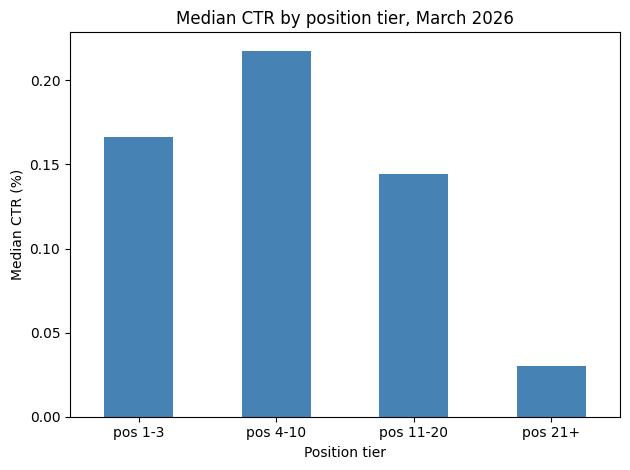

['action_playbook_queue.csv', 'w07_playbook_metrics.json'] ['median_ctr_by_tier.png']


In [12]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import os, json
import matplotlib.pyplot as plt

os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

# 1) The ranked queue (stays out of git by design; the notebook regenerates it)
queue.to_csv("work/outputs/action_playbook_queue.csv", index=False)

# 2) Metrics file: the receipts your paper's numbers trace back to
metrics = {
    "data_month": "2026-03",
    "min_impressions": 200,
    "position_correction": "added 1 to average position (position sum is zero-based)",
    "pages_in_slice": int(len(pages)),
    "pages_in_queue": int(len(queue)),
    "actions": {k: int(v) for k, v in queue["action"].value_counts().items()},
    "reason_codes": {k: int(v) for k, v in queue["reason_code"].value_counts().items()},
    "week6_grouped_auc_rule": 0.774,
    "week6_grouped_auc_random_forest": 0.799,
}
with open("work/outputs/w07_playbook_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# 3) One figure: median CTR by position tier (aggregate only, no client or page details)
tier_ctr = pages.groupby("tier", observed=True)["ctr"].median() * 100
tier_ctr.plot(kind="bar", color="steelblue")
plt.ylabel("Median CTR (%)")
plt.xlabel("Position tier")
plt.title("Median CTR by position tier, March 2026")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("work/figures/median_ctr_by_tier.png", dpi=150)
plt.show()

print(sorted(os.listdir("work/outputs")), sorted(os.listdir("work/figures")))

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.